In [42]:
import sipri # pip install sipri
import pandas as pd
import logging
from itertools import product, combinations

import sys
sys.path.append("..")

from utils import get_all_countries, get_empty_country_df
from network_analysis import get_networks
from community import detect_local_communities
from hegemony import get_hegemony_scores, get_hegemony_top, visualize_hegemony
from countryconverter import convert_country_df
from data_handling import gsheet_handler

from sipri import load_sipri, preprocess_sipri
from interventions import load_interventions, preprocess_interventions, interventions_main

def analysis_main(year_start=2022, rolling_window=30, res_range_start=2, res_range_end=20, one_year_hegemony_threshold=5, min_clients_for_top=3, centrality_threshold=0.5, community_detection='louvian'):
    
    weapon_df = load_sipri()  # Loading the data
    weapon_df, weapon_df_triple = preprocess_sipri(weapon_df, rolling_window=rolling_window, year_start=year_start)  # data preprocessing

    intervention_df = load_interventions()
    intervention_df, intervention_df_triple = preprocess_interventions(intervention_df, rolling_window=rolling_window, year_start=year_start)  # data preprocessing

In [43]:
import pandas as pd
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
import matplotlib as mpl
import csv
from pyvis.network import Network
import pyvis
import pyreadr

In [44]:
def plotWithPyvis(G, notebook_plotting=True, improve_view=True, heading=""):

    #labels = make_label_dict(labels)
    
    net = Network(notebook=notebook_plotting, height='800px', width='1300px', heading=heading)
    net.from_nx(G)
    net.inherit_edge_colors = False
    
    #for i in range (0,len(labels)):
        #country = labels[net.nodes[i]['label']]
        #net.nodes[i]['label'] = country
        
    """if status[country] == 'superpower':
        net.nodes[i]['size'] = 50
        net.nodes[i]['mass'] = 50
    if status[country] == 'great_power':
        net.nodes[i]['size'] = 25
        net.nodes[i]['mass'] = 25
    if status[country] == 'middle_power':
        net.nodes[i]['size'] = 15
        net.nodes[i]['mass'] = 15
    if status[country] == 'small_power':
        net.nodes[i]['size'] = 7
        net.nodes[i]['mass'] = 7
    if status[country] == 'microstate':
        net.nodes[i]['size'] = 4
        net.nodes[i]['mass'] = 4"""
    #    pass
    #настройка толщины
    #for i in range (0,len(net.edges)):
        #country = labels[net.nodes[i]['label']]
        #net.edges[i]['value'] = net.edges[i]['weight'] / 10
    #    net.edges[i]['width'] = net.edges[i]['weight'] / 2 #for cosmetics
    net.set_options(
    """
    const options = {
      "nodes": {
        "font": {
          "size": 21
        }
      },
      "edges": {
        "color": {
          "opacity": 0.25
        }
      },
      "physics": {
        "barnesHut": {
          "gravitationalConstant": -4050,
          "centralGravity": 3.1,
          "springLength": 175
        },
      "minVelocity": 0.75
      }
    }
    """)
    #настройка всего
    #net.set_options(
    """
    var options = {
      "nodes": {
        "color": {
          "border": "rgba(233,172,190,1)"
        },
          "font": {
            "size": 40
          }
      },
      "edges": {
        "color": {
          "color": "rgba(93,226,185,0.33)",
          "inherit": false
        },
        "smooth": false
      },
      "physics": {
        "barnesHut": {
          "gravitationalConstant": -300,
          "springConstant": 0.035,
          "damping": 0.4
          }
      }
    }"""#)

 #   net.show_buttons(filter_=['physics'])
 #   net.show_buttons()
    return net

In [45]:
%load_ext autoreload

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [46]:
%autoreload 2

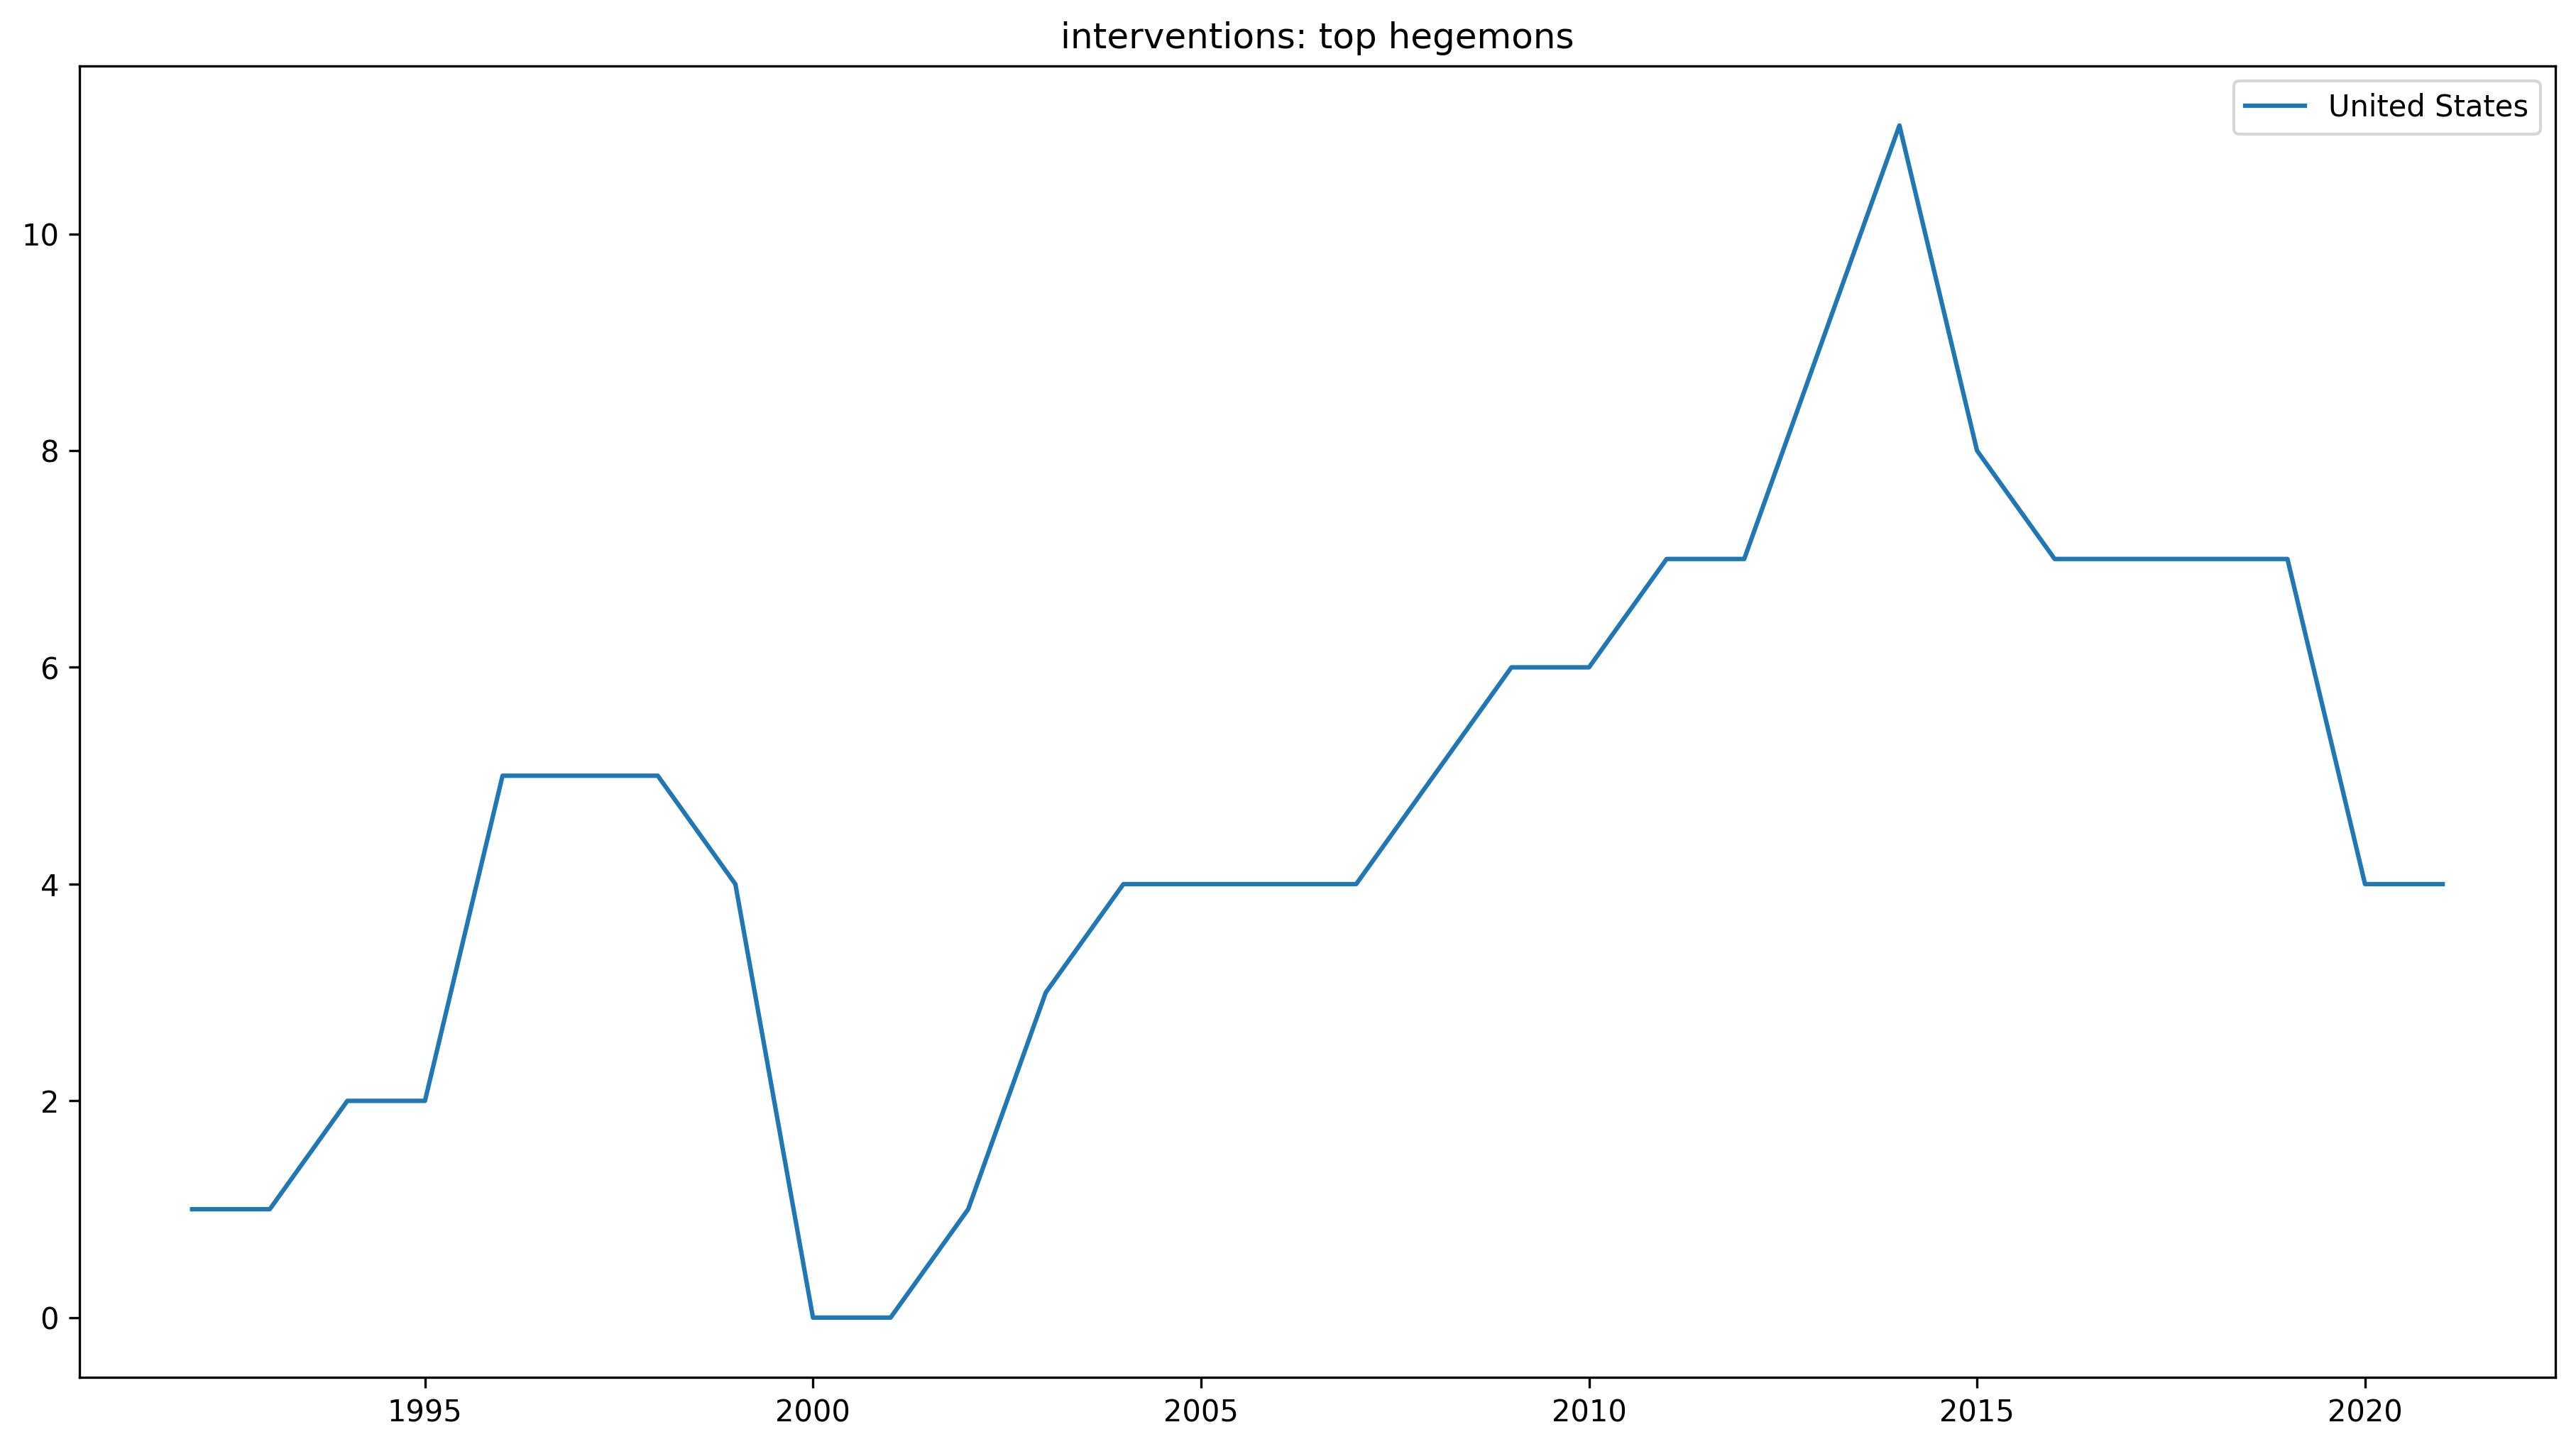

In [47]:
networks, communities, hegemony_df, hegemony_top = interventions_main()

In [49]:
net=plotWithPyvis(networks[2022])
net.show("trade_network.html")

trade_network.html
